# UTS Data Mining: EDA dan Klasterisasi Deret Waktu Multivariat Sensor Boiler

**Dataset:** *A long-tailed distribution time-series dataset in boiler equipment* (Hu dkk., *Scientific Data*, 2025),
berkas mentah `xinan_uncompleted_data.csv` (30 sensor, 86.400 sampel, interval 5 detik).
Sumber: [Kaggle](https://www.kaggle.com/datasets/nikitamanaenkov/time-series-of-industrial-boiler-operations) ·
[figshare](https://figshare.com/articles/dataset/A_long-tailed_distribution_time-series_dataset_in_boiler_equipment/28822793)

**Alur notebook**

1. Pemahaman data: struktur, interval waktu, nilai hilang
2. EDA: statistik deskriptif dan ketimpangan skala, distribusi, pencilan, korelasi, ketergantungan waktu
3. Praproses: imputasi, winsorizing pencilan ekstrem, *robust scaling*
4. Representasi temporal: fitur jendela geser (mean, std, slope), lalu PCA (kriteria Kaiser)
5. Klasterisasi K-Means: pemilihan *k* dengan Elbow, Silhouette, dan Davies–Bouldin
6. Perbandingan dengan *baseline* (K-Means titik per titik dan rata-rata jendela), serta uji sensitivitas panjang jendela
7. Interpretasi klaster terhadap suhu uap keluaran boiler (TE_8332A) sebagai acuan eksternal

> **Google Colab:** unggah `xinan_uncompleted_data.csv` ke panel *Files*, lalu jalankan semua sel (*Runtime → Run all*).

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
DATA_PATH = "xinan_uncompleted_data.csv"
FIG, OUT = "figures", "outputs"
os.makedirs(FIG, exist_ok=True); os.makedirs(OUT, exist_ok=True)

# Palet: kategorikal berurutan tetap (lolos uji buta warna), divergen biru–abu–merah
CL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "serif", "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.2,
})
def save(fig, name):
    fig.savefig(f"{FIG}/{name}.png"); plt.show()

## 1. Pemahaman Data

In [2]:
raw = pd.read_csv(DATA_PATH, parse_dates=["date"]).set_index("date")
raw.columns = [c.replace(".AV_0#", "") for c in raw.columns]
REF = "TE_8332A"                       # suhu uap keluaran boiler: acuan eksternal, bukan fitur klaster
FEAT = [c for c in raw.columns if c != REF]

dt = raw.index.to_series().diff().dt.total_seconds()
print("Ukuran data       :", raw.shape)
print("Rentang waktu     :", raw.index.min(), "s.d.", raw.index.max())
print("Interval sampling :", dt.value_counts().to_dict(), "detik")
print("Timestamp duplikat:", raw.index.duplicated().sum())
print("Fitur klasterisasi:", len(FEAT), "sensor  |  acuan eksternal:", REF)

Ukuran data       : (86400, 30)
Rentang waktu     : 2022-03-27 14:28:54 s.d. 2022-04-01 14:28:49
Interval sampling : {5.0: 86399} detik
Timestamp duplikat: 0
Fitur klasterisasi: 29 sensor  |  acuan eksternal: TE_8332A


In [3]:
DESC = {
 "PT_8313A": "Upper furnace pressure (A)", "PT_8313B": "Upper furnace pressure (B)", "PT_8313C": "Upper furnace pressure (C)",
 "PT_8313D": "Upper furnace pressure (D)", "PT_8313E": "Upper furnace pressure (E)", "PT_8313F": "Upper furnace pressure (F)",
 "PTCA_8324": "Container outlet vapour pressure", "PTCA_8322A": "Pot pressure (left)",
 "TE_8319A": "Flue gas temp. upper economizer outlet (left)", "TE_8319B": "Flue gas temp. upper economizer outlet (right)",
 "TE_8313B": "Upper furnace chamber temp. (right)", "TE_8303": "Primary air preheater outlet temp.",
 "TE_8304": "Secondary air preheater outlet temp.", "TE_8332A": "Boiler outlet steam temp.",
 "TV_8329ZC": "Primary desuperheater regulating valve", "FT_8301": "Primary fan outlet flow", "FT_8302": "Secondary fan outlet flow",
 "FT_8306A": "Return air chamber flow (left)", "FT_8306B": "Return air chamber flow (right)",
 "AIR_8301A": "Economiser inlet flue gas O2 (left)", "AIR_8301B": "Economiser inlet flue gas O2 (right)",
 "YFJ3_AI": "Induced draft fan motor current", "YFJ3_ZD1": "ID fan bearing vibration (A)", "YFJ3_ZD2": "ID fan bearing vibration (B)",
 "SXLTCYZ": "Upper-lower hearth diff. pressure (left)", "SXLTCYY": "Upper-lower hearth diff. pressure (right)",
 "ZCLCCY": "Left layer diff. pressure", "YCLCCY": "Right layer diff. pressure",
 "YJJWSLL": "Primary desuperheating water flow", "ZZQBCHLL": "Main steam flow (compensated)",
}
GROUP = {c: ("Tekanan" if c.startswith(("PT", "SXL", "ZCL", "YCL")) else "Suhu" if c.startswith(("TE",))
             else "Aliran" if c.startswith(("FT", "YJJ", "ZZQ")) else "Oksigen" if c.startswith("AIR")
             else "Getaran/arus" if c.startswith("YFJ") else "Katup") for c in raw.columns}
miss = raw.isna().sum()
info = pd.DataFrame({"deskripsi": pd.Series(DESC), "kelompok": pd.Series(GROUP),
                     "nilai_hilang": miss, "unik": raw.nunique()}).loc[raw.columns]
info

,deskripsi,kelompok,nilai_hilang,unik
PT_8313A,Upper furnace pressure (A),Tekanan,0,4132
PT_8313B,Upper furnace pressure (B),Tekanan,0,4038
PT_8313C,Upper furnace pressure (C),Tekanan,0,3826
PT_8313D,Upper furnace pressure (D),Tekanan,0,3874
PT_8313E,Upper furnace pressure (E),Tekanan,0,4145
PT_8313F,Upper furnace pressure (F),Tekanan,0,4033
PTCA_8322A,Pot pressure (left),Tekanan,0,68
PTCA_8324,Container outlet vapour pressure,Tekanan,0,72
TE_8319A,Flue gas temp. upper economizer outlet (left),Suhu,0,2883
TE_8319B,Flue gas temp. upper economizer outlet (right),Suhu,0,4425


In [4]:
gap_idx = np.where(raw["YJJWSLL"].isna())[0]
blocks = np.split(gap_idx, np.where(np.diff(gap_idx) != 1)[0] + 1)
for b in blocks:
    print(f"YJJWSLL kosong: indeks {b[0]}–{b[-1]} ({len(b)} sampel = {len(b)*5} detik), "
          f"{raw.index[b[0]]} s.d. {raw.index[b[-1]]}")

YJJWSLL kosong: indeks 11442–11469 (28 sampel = 140 detik), 2022-03-28 06:22:24 s.d. 2022-03-28 06:24:39
YJJWSLL kosong: indeks 45670–45671 (2 sampel = 10 detik), 2022-03-30 05:54:44 s.d. 2022-03-30 05:54:49


## 2. Exploratory Data Analysis
### 2.1 Statistik deskriptif dan ketimpangan skala

In [5]:
desc = raw.describe().T
desc["median"] = raw.median()
desc["skewness"] = raw.skew()
desc["kurtosis"] = raw.kurt()
desc["rentang"] = desc["max"] - desc["min"]
desc["CV_%"] = 100 * desc["std"] / desc["mean"].abs()
desc = desc[["count", "mean", "std", "min", "median", "max", "rentang", "skewness", "kurtosis", "CV_%"]]
desc.round(3).to_csv(f"{OUT}/statistik_deskriptif.csv")
print(f"Rasio rentang terbesar/terkecil: {desc['rentang'].max() / desc['rentang'].min():,.0f}x "
      f"({desc['rentang'].idxmax()} vs {desc['rentang'].idxmin()})")
print(f"Rasio |mean| terbesar/terkecil : {desc['mean'].abs().max() / desc['mean'].abs().min():,.0f}x")
desc.round(2)

Rasio rentang terbesar/terkecil: 28,598x (FT_8302 vs PTCA_8322A)


Rasio |mean| terbesar/terkecil : 22,257x


,count,mean,std,min,median,max,rentang,skewness,kurtosis,CV_%
PT_8313A,86400.0,-137.71,55.38,-484.70,-135.32,75.33,560.03,-0.61,1.75,40.22
PT_8313B,86400.0,-188.61,53.90,-549.57,-186.76,51.83,601.40,-0.62,2.09,28.58
PT_8313C,86400.0,-153.34,51.31,-509.12,-151.43,126.28,635.40,-0.66,2.55,33.46
PT_8313D,86400.0,-118.44,52.45,-501.23,-116.52,256.53,757.76,-0.70,3.20,44.28
PT_8313E,86400.0,-167.36,56.80,-586.83,-165.36,245.11,831.94,-0.69,3.20,33.94
PT_8313F,86400.0,-156.95,55.65,-562.75,-154.96,174.87,737.62,-0.68,2.82,35.46
PTCA_8322A,86400.0,9.77,0.08,9.42,9.77,10.09,0.67,-0.56,1.51,0.77
PTCA_8324,86400.0,9.44,0.07,9.06,9.45,9.77,0.71,-0.76,2.43,0.77
TE_8319A,86400.0,356.88,5.99,342.53,357.30,376.50,33.97,-0.04,-0.55,1.68
TE_8319B,86400.0,390.97,9.15,367.29,390.79,420.58,53.29,-0.08,-0.32,2.34


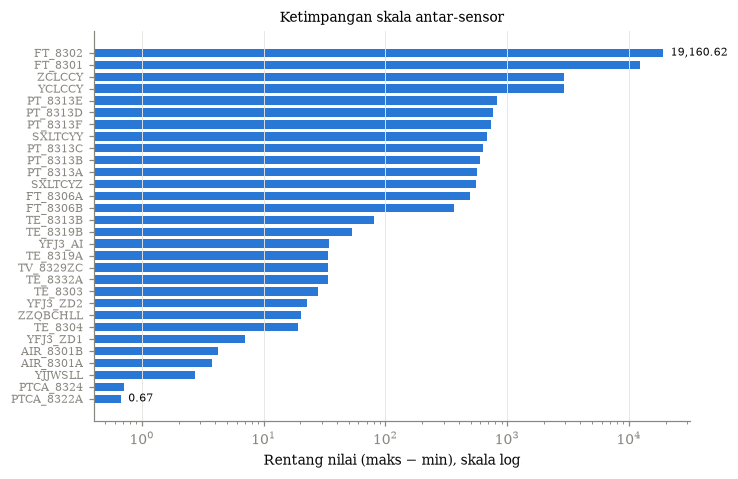

In [6]:
r = desc["rentang"].sort_values()
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(r.index, r.values, color=CL[0], height=0.7)
ax.set_xscale("log"); ax.set_xlabel("Rentang nilai (maks − min), skala log")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=7)
for y, v in enumerate(r.values):
    if y in (0, len(r) - 1): ax.text(v * 1.15, y, f"{v:,.2f}", va="center", fontsize=7, color=INK)
ax.set_title("Ketimpangan skala antar-sensor")
save(fig, "fig02_ketimpangan_skala")

### 2.2 Pola deret waktu (rata-rata 5 menit)

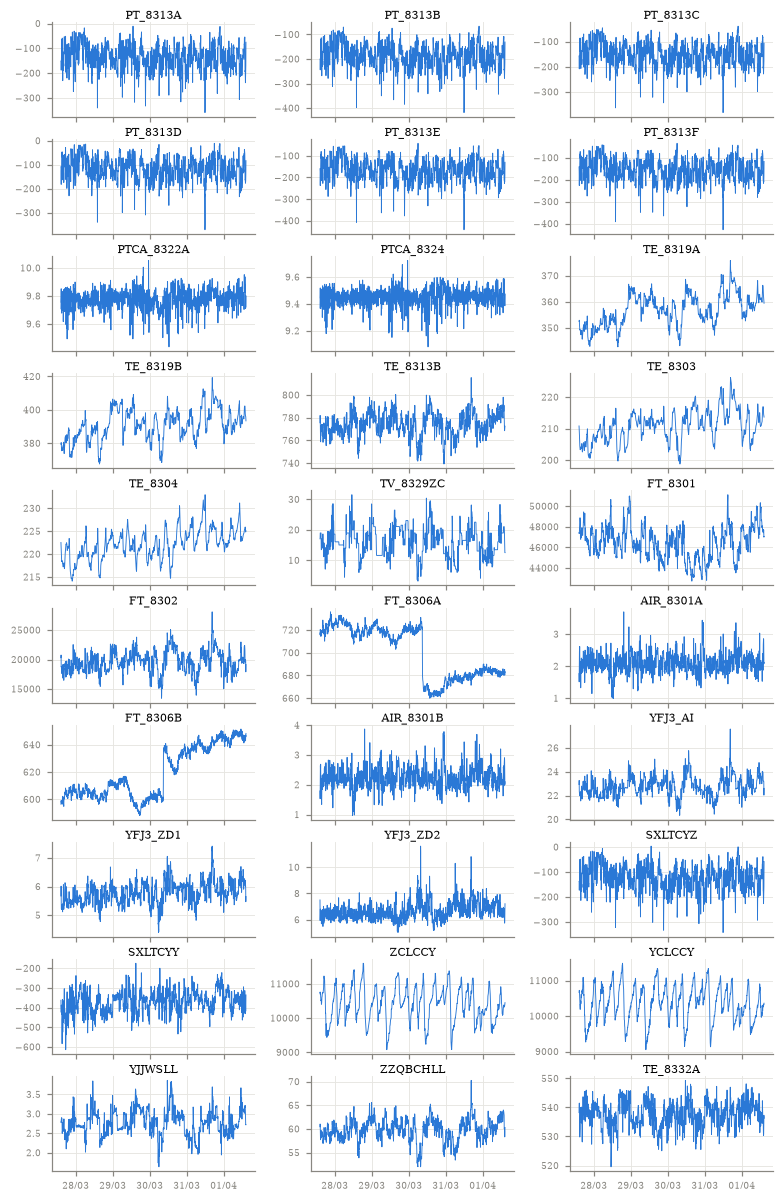

In [7]:
m5 = raw.resample("5min").mean()
fig, axes = plt.subplots(10, 3, figsize=(7.2, 11), sharex=True)
for ax, c in zip(axes.ravel(), raw.columns):
    ax.plot(m5.index, m5[c], color=CL[0], lw=0.6)
    ax.set_title(c, fontsize=7, pad=2); ax.tick_params(labelsize=6)
for ax in axes[-1]:
    ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m")); ax.tick_params(axis="x", rotation=0)
fig.tight_layout(h_pad=0.4)
save(fig, "fig03_deret_waktu_30_sensor")

Pengamatan: proses berjalan kontinu tanpa *shutdown*. Pada FT_8306A/FT_8306B terlihat pergeseran level yang tajam sekitar
30 Maret, sedangkan ZCLCCY/YCLCCY membentuk pola gigi gergaji periodik (siklus akumulasi dan pembuangan material lapisan).
Sensor tekanan tungku (PT_8313A–F) berfluktuasi cepat.

### 2.3 Distribusi suhu uap keluaran boiler (acuan *long-tailed*)

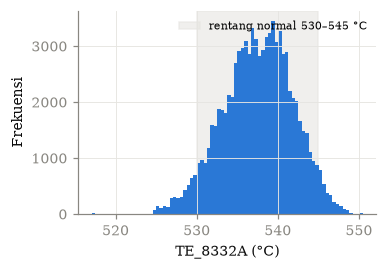

Di luar 530–545 °C: 8.14% sampel  (skewness = -0.25)


In [8]:
t = raw[REF]
abn = (t < 530) | (t > 545)
fig, ax = plt.subplots(figsize=(3.5, 2.4))
ax.hist(t, bins=80, color=CL[0])
ax.axvspan(530, 545, color=GRID, alpha=0.6, zorder=0, label="rentang normal 530–545 °C")
ax.set_xlabel("TE_8332A (°C)"); ax.set_ylabel("Frekuensi"); ax.legend(fontsize=7, frameon=False)
save(fig, "fig04_distribusi_suhu_uap")
print(f"Di luar 530–545 °C: {abn.mean()*100:.2f}% sampel  (skewness = {t.skew():.2f})")

### 2.4 Pencilan: boxplot (skala robust) dan aturan IQR

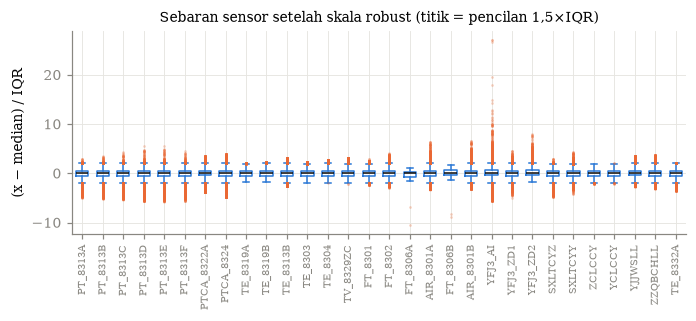

,IQR_1.5x,IQR_1.5x_%,IQR_3x (ekstrem),IQR_3x_%
PTCA_8324,3352,3.88,417,0.48
AIR_8301A,2970,3.44,247,0.29
AIR_8301B,2933,3.39,313,0.36
PTCA_8322A,2600,3.01,61,0.07
YFJ3_ZD2,2175,2.52,224,0.26
YFJ3_AI,1951,2.26,557,0.64
ZZQBCHLL,1710,1.98,36,0.04
YFJ3_ZD1,1433,1.66,47,0.05
YJJWSLL,1346,1.56,2,0.00
TE_8313B,1247,1.44,0,0.00


In [9]:
q1, q3 = raw.quantile(0.25), raw.quantile(0.75); iqr = q3 - q1
out15 = ((raw < q1 - 1.5 * iqr) | (raw > q3 + 1.5 * iqr)).sum()
out30 = ((raw < q1 - 3.0 * iqr) | (raw > q3 + 3.0 * iqr)).sum()
outl = pd.DataFrame({"IQR_1.5x": out15, "IQR_1.5x_%": 100 * out15 / len(raw),
                     "IQR_3x (ekstrem)": out30, "IQR_3x_%": 100 * out30 / len(raw)}).round(2)
outl.to_csv(f"{OUT}/pencilan_iqr.csv")

rs = (raw - raw.median()) / iqr          # robust z: agar 30 sensor sebanding dalam satu sumbu
fig, ax = plt.subplots(figsize=(7.2, 2.4))
ax.boxplot([rs[c].dropna() for c in raw.columns], whis=1.5, widths=0.6, showfliers=True,
           flierprops=dict(marker=".", markersize=1.5, markeredgecolor=CL[1], alpha=0.3),
           medianprops=dict(color=INK), boxprops=dict(color=CL[0]), whiskerprops=dict(color=CL[0]), capprops=dict(color=CL[0]))
ax.set_xticks(range(1, len(raw.columns) + 1), raw.columns, rotation=90, fontsize=6.5)
ax.set_ylabel("(x − median) / IQR"); ax.set_title("Sebaran sensor setelah skala robust (titik = pencilan 1,5×IQR)")
save(fig, "fig05_boxplot_pencilan")
outl.sort_values("IQR_1.5x", ascending=False)

### 2.5 Korelasi antar-sensor

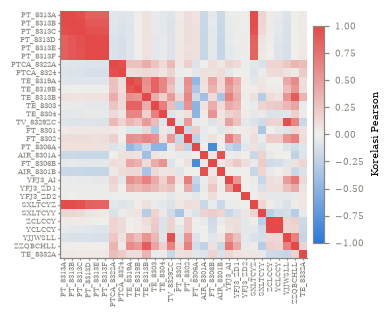

PT_8313E    PT_8313F     0.992
PT_8313D    PT_8313E     0.991
            PT_8313F     0.987
PT_8313B    PT_8313C     0.982
ZCLCCY      YCLCCY       0.977
PT_8313A    PT_8313B     0.977
            SXLTCYZ      0.972
PT_8313B    SXLTCYZ      0.963
PT_8313A    PT_8313C     0.960
PTCA_8322A  PTCA_8324    0.947
PT_8313C    PT_8313D     0.946
TV_8329ZC   YJJWSLL      0.946
dtype: float64

In [10]:
corr = raw.corr()
fig, ax = plt.subplots(figsize=(3.5, 3.2))      # ukuran satu kolom paper IEEE
im = ax.imshow(corr, cmap=DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=4.6)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=4.6); ax.grid(False)
ax.tick_params(length=1.5, pad=1)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cb.set_label("Korelasi Pearson", fontsize=6.5); cb.ax.tick_params(labelsize=6)
save(fig, "fig06_matriks_korelasi")

up = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
top = up.reindex(up.abs().sort_values(ascending=False).index).head(12).round(3)
top.to_csv(f"{OUT}/pasangan_korelasi_tertinggi.csv"); top

### 2.6 Ketergantungan waktu (autokorelasi)

Median autokorelasi antar-sensor: {'5 dtk': 0.988, '1 mnt': 0.914, '5 mnt': 0.654, '30 mnt': 0.429, '1 jam': 0.317}


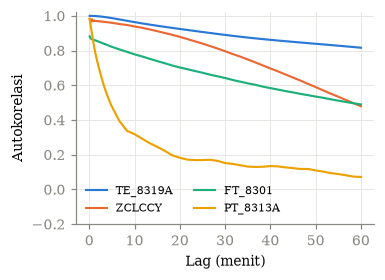

,5 dtk,1 mnt,5 mnt,30 mnt,1 jam
PT_8313A,0.981,0.832,0.477,0.152,0.072
PT_8313B,0.986,0.836,0.491,0.167,0.082
PT_8313C,0.987,0.834,0.503,0.168,0.081
PT_8313D,0.980,0.824,0.508,0.164,0.076
PT_8313E,0.985,0.829,0.512,0.168,0.083
PT_8313F,0.988,0.846,0.518,0.169,0.082
PTCA_8322A,0.998,0.957,0.436,0.149,0.054
PTCA_8324,0.998,0.947,0.363,0.092,0.005
TE_8319A,1.000,0.999,0.987,0.890,0.816
TE_8319B,1.000,0.999,0.985,0.840,0.701


In [11]:
LAGS = {"5 dtk": 1, "1 mnt": 12, "5 mnt": 60, "30 mnt": 360, "1 jam": 720}
acf = pd.DataFrame({k: raw.apply(lambda s: s.autocorr(l)) for k, l in LAGS.items()}).round(3)
acf.to_csv(f"{OUT}/autokorelasi.csv")
print("Median autokorelasi antar-sensor:", acf.median().round(3).to_dict())

lags = np.unique(np.r_[np.arange(1, 60, 2), np.arange(60, 721, 20)])
show = ["TE_8319A", "ZCLCCY", "FT_8301", "PT_8313A"]
fig, ax = plt.subplots(figsize=(3.5, 2.5))
for i, c in enumerate(show):
    ax.plot(lags * 5 / 60, [raw[c].autocorr(int(l)) for l in lags], color=CL[i], lw=1.4, label=c)
ax.set_xlabel("Lag (menit)"); ax.set_ylabel("Autokorelasi"); ax.set_ylim(-0.2, 1.02)
ax.legend(fontsize=7, frameon=False, ncol=2)
save(fig, "fig07_autokorelasi")
acf

## 3. Praproses

1. **Nilai hilang:** interpolasi linear berbasis waktu. Celah terpanjang hanya 28 sampel (140 detik), sehingga interpolasi lokal memadai.
   Paper data memakai AutoReg; interpolasi linear dipilih karena sederhana dan celahnya pendek.
2. **Pencilan:** *winsorizing* pada pagar Tukey 3×IQR (pencilan ekstrem). Nilai tidak dibuang, hanya dipotong ke batas pagar,
   sehingga urutan waktu tetap utuh. Pagar 1,5×IQR tidak dipakai karena akan memotong variasi operasi yang sah.
3. **Penskalaan:** `RobustScaler` (median dan IQR) agar tahan terhadap ekor panjang dan menghilangkan ketimpangan skala.

In [12]:
X = raw.interpolate(method="time")
assert X.isna().sum().sum() == 0

lo, hi = q1 - 3 * iqr, q3 + 3 * iqr
clipped = ((X[FEAT] < lo[FEAT]) | (X[FEAT] > hi[FEAT])).sum()
X[FEAT] = X[FEAT].clip(lo[FEAT], hi[FEAT], axis=1)
print(f"Nilai di-winsorize: {clipped.sum():,} dari {X[FEAT].size:,} sel ({100*clipped.sum()/X[FEAT].size:.3f}%)")

Z = pd.DataFrame(RobustScaler().fit_transform(X[FEAT]), index=X.index, columns=FEAT)
pd.DataFrame({"sebelum: std": X[FEAT].std(), "sesudah: std": Z.std()}).describe().loc[["min", "max"]].round(3)

Nilai di-winsorize: 3,843 dari 2,505,600 sel (0.153%)


,sebelum: std,sesudah: std
min,0.072,0.556
max,2094.556,0.902


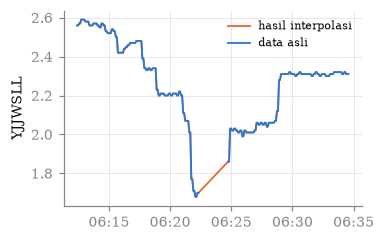

In [13]:
b = blocks[0]; s0, s1 = b[0] - 120, b[-1] + 120
fig, ax = plt.subplots(figsize=(3.5, 2.3))
ax.plot(X.index[s0:s1], X["YJJWSLL"].iloc[s0:s1], color=CL[1], lw=1.2, label="hasil interpolasi")
ax.plot(raw.index[s0:s1], raw["YJJWSLL"].iloc[s0:s1], color=CL[0], lw=1.2, label="data asli")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M"))
ax.set_ylabel("YJJWSLL"); ax.legend(fontsize=7, frameon=False)
save(fig, "fig08_imputasi_yjjwsll")

## 4. Representasi Temporal: Fitur Jendela Geser

Deret dipotong menjadi jendela **tidak tumpang-tindih** sepanjang `W` sampel (W = 60, yaitu 5 menit). Untuk tiap sensor di tiap jendela dihitung:

- **mean**: level operasi,
- **std**: volatilitas atau stabilitas,
- **slope**: arah tren (kemiringan regresi linear terhadap waktu).

Jendela tidak dibuat tumpang-tindih supaya sampel klaster tidak saling duplikat, karena duplikasi semu akan menggelembungkan Silhouette.
Fitur kemudian distandardisasi, lalu direduksi dengan PCA menggunakan **kriteria Kaiser** (eigenvalue > 1).

Jendela: 1440 × 87 fitur  ->  PCA Kaiser: 26 komponen, varians terjelaskan 86.1%


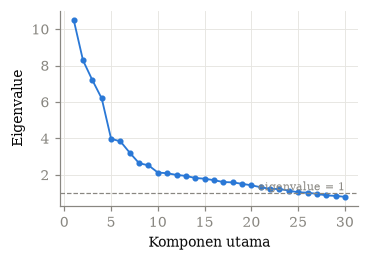

In [14]:
def window_features(Z, W, kind="full"):
    n = len(Z) // W * W
    arr = Z.values[:n].reshape(-1, W, Z.shape[1])
    idx = Z.index[:n:W]
    parts = [pd.DataFrame(arr.mean(1), index=idx, columns=Z.columns).add_suffix("_mean")]
    if kind == "full":
        tc = np.arange(W) - (W - 1) / 2
        parts.append(pd.DataFrame(arr.std(1, ddof=1), index=idx, columns=Z.columns).add_suffix("_std"))
        parts.append(pd.DataFrame((arr * tc[None, :, None]).sum(1) / (tc ** 2).sum(), index=idx, columns=Z.columns).add_suffix("_slope"))
    return pd.concat(parts, axis=1)

def embed(F):
    S = StandardScaler().fit_transform(F)
    p = PCA(random_state=SEED).fit(S)
    n = int((p.explained_variance_ > 1).sum())
    return S @ p.components_[:n].T, p, n

W = 60
Fw = window_features(Z, W)
assert Fw.shape == (len(Z) // W, 3 * len(FEAT))
P, pca, n_pc = embed(Fw)
print(f"Jendela: {Fw.shape[0]} × {Fw.shape[1]} fitur  ->  PCA Kaiser: {n_pc} komponen, "
      f"varians terjelaskan {pca.explained_variance_ratio_[:n_pc].sum()*100:.1f}%")

fig, ax = plt.subplots(figsize=(3.5, 2.3))
ev = pca.explained_variance_[:30]
ax.plot(range(1, len(ev) + 1), ev, "o-", color=CL[0], ms=3)
ax.axhline(1, color=MUTED, ls="--", lw=0.8); ax.text(len(ev), 1.15, "eigenvalue = 1", ha="right", fontsize=7, color=MUTED)
ax.set_xlabel("Komponen utama"); ax.set_ylabel("Eigenvalue")
save(fig, "fig09_scree_pca")

## 5. Klasterisasi K-Means dan Pemilihan Jumlah Klaster

In [15]:
K_RANGE = range(2, 11)

def knee(ks, y):
    # Elbow: titik dengan jarak terjauh dari garis lurus ujung-ke-ujung kurva WCSS ternormalisasi
    x = (np.array(ks) - ks[0]) / (ks[-1] - ks[0]); y = np.array(y); y = (y - y.min()) / (y.max() - y.min())
    return ks[int(np.argmax(np.abs(y - (1 - x))))]

def sweep(E, sample=None):
    rows = []
    for k in K_RANGE:
        km = KMeans(k, n_init=10, random_state=SEED).fit(E)
        rows.append({"k": k, "WCSS": km.inertia_,
                     "Silhouette": silhouette_score(E, km.labels_, sample_size=sample, random_state=SEED),
                     "DBI": davies_bouldin_score(E, km.labels_)})
    return pd.DataFrame(rows).set_index("k")

res = sweep(P)
k_elbow = knee(list(K_RANGE), res["WCSS"])
k_sil, k_dbi = res["Silhouette"].idxmax(), res["DBI"].idxmin()
res.round(4).to_csv(f"{OUT}/evaluasi_k_usulan.csv")
print(f"k Elbow = {k_elbow} | k Silhouette maks = {k_sil} | k DBI min = {k_dbi}")
res.round(4)

k Elbow = 5 | k Silhouette maks = 2 | k DBI min = 7


,WCSS,Silhouette,DBI
k,,,
2,98767.4679,0.2595,2.4080
3,92151.7787,0.0746,2.8001
4,86570.2483,0.0721,2.5120
5,83003.0066,0.0685,2.4015
6,80702.5155,0.0639,2.5522
7,78655.3440,0.0695,2.3191
8,76735.9719,0.0543,2.3741
9,75233.5116,0.0512,2.4192
10,73462.1881,0.0539,2.3881


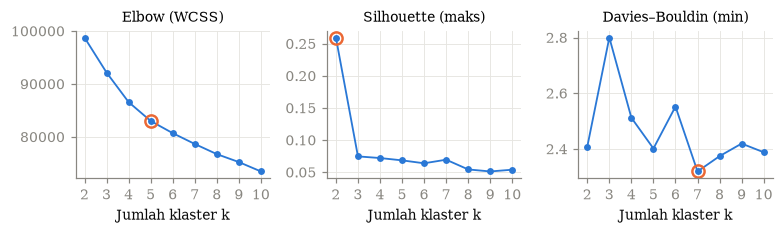

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.2))
for ax, col, kk, lab in zip(axes, ["WCSS", "Silhouette", "DBI"], [k_elbow, k_sil, k_dbi],
                            ["Elbow (WCSS)", "Silhouette (maks)", "Davies–Bouldin (min)"]):
    ax.plot(res.index, res[col], "o-", color=CL[0], ms=3.5)
    ax.plot(kk, res.loc[kk, col], "o", ms=8, mfc="none", mec=CL[1], mew=1.6)
    ax.set_title(lab); ax.set_xlabel("Jumlah klaster k"); ax.set_xticks(list(K_RANGE))
fig.tight_layout()
save(fig, "fig10_elbow_silhouette_dbi")

**Aturan pemilihan k.** Kurva WCSS turun landai tanpa siku tajam, sehingga Elbow saja tidak tegas. Karena itu,
*k* final ditetapkan dari **Silhouette tertinggi**, sedangkan Elbow dan DBI dipakai sebagai pembanding.

In [17]:
K = int(k_sil)
km = KMeans(K, n_init=10, random_state=SEED).fit(P)
lab = pd.Series(km.labels_, index=Fw.index, name="klaster")
sil_final, dbi_final = silhouette_score(P, lab), davies_bouldin_score(P, lab)
print(f"k = {K} | Silhouette = {sil_final:.4f} | DBI = {dbi_final:.4f}")
print("Ukuran klaster:", lab.value_counts().sort_index().to_dict())

k = 2 | Silhouette = 0.2595 | DBI = 2.4080
Ukuran klaster: {0: 1258, 1: 182}


## 6. Perbandingan dengan Baseline dan Sensitivitas Panjang Jendela

In [18]:
# A: K-Means titik per titik (tiap sampel 5 detik independen, tanpa representasi temporal)
PA, _, nA = embed(Z)
resA = sweep(PA, sample=10000)        # Silhouette disampel 10.000 titik karena O(n^2)
# B: rata-rata jendela saja (setara downsampling, tanpa std/slope)
PB, _, nB = embed(window_features(Z, W, "mean"))
resB = sweep(PB)

def best(r): k = r["Silhouette"].idxmax(); return k, r.loc[k, "Silhouette"], r.loc[k, "DBI"]
cmp = pd.DataFrame([
    ["A. Titik per titik (baseline)", len(PA), nA, *best(resA)],
    ["B. Rata-rata jendela 5 menit", len(PB), nB, *best(resB)],
    ["C. Usulan: mean+std+slope jendela 5 menit", len(P), n_pc, *best(res)],
], columns=["Representasi", "n sampel", "n PC", "k terbaik", "Silhouette", "DBI"]).set_index("Representasi")
cmp.round(4).to_csv(f"{OUT}/perbandingan_representasi.csv")
pd.concat({"A": resA, "B": resB, "C": res}, axis=1).round(4).to_csv(f"{OUT}/evaluasi_k_semua_representasi.csv")
cmp.round(4)

,n sampel,n PC,k terbaik,Silhouette,DBI
Representasi,,,,,
A. Titik per titik (baseline),86400,8,2,0.1656,2.0193
B. Rata-rata jendela 5 menit,1440,8,2,0.1738,1.9553
C. Usulan: mean+std+slope jendela 5 menit,1440,26,2,0.2595,2.4080


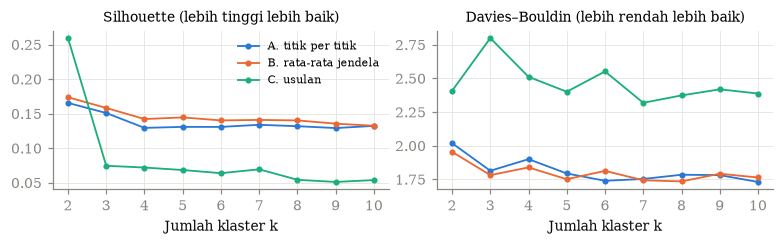

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.3))
for i, (name, r) in enumerate({"A. titik per titik": resA, "B. rata-rata jendela": resB, "C. usulan": res}.items()):
    axes[0].plot(r.index, r["Silhouette"], "o-", color=CL[i], ms=3, label=name)
    axes[1].plot(r.index, r["DBI"], "o-", color=CL[i], ms=3, label=name)
axes[0].set_title("Silhouette (lebih tinggi lebih baik)"); axes[1].set_title("Davies–Bouldin (lebih rendah lebih baik)")
for ax in axes: ax.set_xlabel("Jumlah klaster k"); ax.set_xticks(list(K_RANGE))
axes[0].legend(fontsize=7, frameon=False)
fig.tight_layout()
save(fig, "fig11_perbandingan_representasi")

In [20]:
sens = []
for w in (12, 60, 120, 360):
    Pw, _, nw = embed(window_features(Z, w))
    for k in (2, 3, 4):
        l = KMeans(k, n_init=10, random_state=SEED).fit_predict(Pw)
        sens.append({"W (sampel)": w, "durasi": f"{w*5//60} mnt", "n jendela": len(Pw), "k": k,
                     "Silhouette": silhouette_score(Pw, l), "DBI": davies_bouldin_score(Pw, l)})
sens = pd.DataFrame(sens).round(4)
sens.to_csv(f"{OUT}/sensitivitas_jendela.csv", index=False)
sens.pivot(index=["W (sampel)", "durasi"], columns="k", values=["Silhouette", "DBI"])

Silhouette                     DBI                
k                          2       3       4       2       3       4
W (sampel) durasi                                                   
12         1 mnt      0.0783  0.0793  0.0689  3.2545  2.6610  2.5477
60         5 mnt      0.2595  0.0746  0.0721  2.4080  2.8001  2.5120
120        10 mnt     0.2002  0.1560  0.0713  2.6643  2.4502  2.4955
360        30 mnt     0.1131  0.0911  0.0902  2.9849  2.6215  2.4164

## 7. Interpretasi Klaster

In [21]:
# Profil: rata-rata fitur per klaster dalam satuan z (relatif terhadap seluruh jendela)
zf = (Fw - Fw.mean()) / Fw.std()
prof = zf.groupby(lab).mean()
top_feat = prof.abs().max().sort_values(ascending=False).head(14).index
prof[top_feat].T.round(2).to_csv(f"{OUT}/profil_klaster_fitur_teratas.csv")

# Acuan eksternal: suhu uap keluaran (tidak dipakai saat klasterisasi)
n = len(Fw) * W
ref_w = raw[REF].iloc[:n].values.reshape(-1, W)
abn_w = ((ref_w < 530) | (ref_w > 545)).mean(1)
level = X[FEAT].iloc[:n].groupby(np.arange(n) // W).mean().set_index(Fw.index)
summary = pd.DataFrame({
    "jumlah jendela": lab.value_counts().sort_index(),
    "porsi waktu %": (100 * lab.value_counts(normalize=True)).sort_index(),
    "TE_8332A rata-rata (°C)": pd.Series(ref_w.mean(1), index=Fw.index).groupby(lab).mean(),
    "TE_8332A abnormal %": pd.Series(100 * abn_w, index=Fw.index).groupby(lab).mean(),
    "std PT_8313A–F (z)": zf.filter(regex=r"PT_8313._std").mean(axis=1).groupby(lab).mean(),
    "ZZQBCHLL rata-rata": level["ZZQBCHLL"].groupby(lab).mean(),
    "FT_8301 rata-rata": level["FT_8301"].groupby(lab).mean(),
}).round(3)
summary.to_csv(f"{OUT}/ringkasan_klaster.csv")
summary

,jumlah jendela,porsi waktu %,TE_8332A rata-rata (°C),TE_8332A abnormal %,std PT_8313A–F (z),ZZQBCHLL rata-rata,FT_8301 rata-rata
klaster,,,,,,,
0,1258,87.361,537.421,7.546,-0.225,59.707,46415.450
1,182,12.639,538.212,12.280,1.553,60.140,46790.738


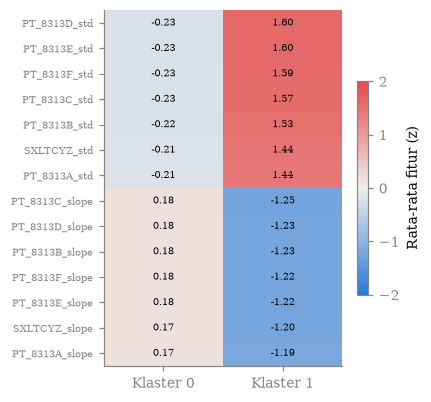

In [22]:
fig, ax = plt.subplots(figsize=(3.5, 4.2))
im = ax.imshow(prof[top_feat].T, cmap=DIV, vmin=-2, vmax=2, aspect="auto")
ax.set_yticks(range(len(top_feat)), top_feat, fontsize=6.5)
ax.set_xticks(range(K), [f"Klaster {c}" for c in range(K)]); ax.grid(False)
for (i, j), v in np.ndenumerate(prof[top_feat].T.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5, color=INK)
fig.colorbar(im, ax=ax, shrink=0.6, label="Rata-rata fitur (z)")
save(fig, "fig12_profil_klaster")

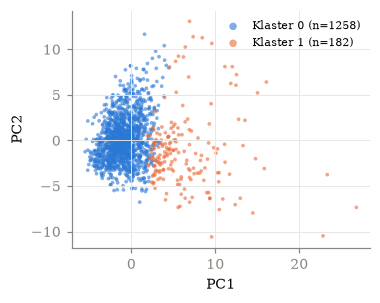

In [23]:
fig, ax = plt.subplots(figsize=(3.5, 2.8))
for c in range(K):
    msk = lab.values == c
    ax.scatter(P[msk, 0], P[msk, 1], s=6, color=CL[c], alpha=0.6, edgecolors="none", label=f"Klaster {c} (n={msk.sum()})")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, frameon=False, markerscale=2)
save(fig, "fig13_sebaran_pca_klaster")

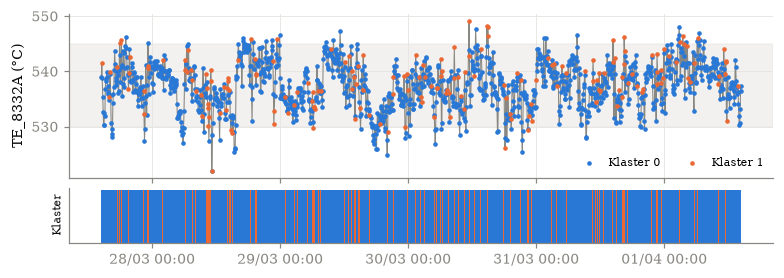

In [24]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 2.6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
a1.plot(Fw.index, ref_w.mean(1), color=MUTED, lw=0.7)
for c in range(K):
    msk = lab.values == c
    a1.scatter(Fw.index[msk], ref_w.mean(1)[msk], s=4, color=CL[c], label=f"Klaster {c}", zorder=3)
a1.axhspan(530, 545, color=GRID, alpha=0.5, zorder=0)
a1.set_ylabel("TE_8332A (°C)"); a1.legend(fontsize=7, frameon=False, ncol=K, loc="lower right")
a2.bar(Fw.index, 1, width=W * 5 / 86400, color=[CL[c] for c in lab.values], linewidth=0)
a2.set_yticks([]); a2.grid(False); a2.set_ylabel("Klaster", fontsize=7)
a2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%d/%m %H:%M"))
fig.tight_layout(h_pad=0.3)
save(fig, "fig14_linimasa_klaster")

In [25]:
lab.to_frame().assign(**{f"PC{i+1}": P[:, i] for i in range(min(3, n_pc))}).to_csv(f"{OUT}/label_klaster_per_jendela.csv")
print("Selesai. Gambar di folder", FIG, "| tabel di folder", OUT)

Selesai. Gambar di folder figures | tabel di folder outputs
